In [93]:
%reload_ext autoreload
%autoreload 2

import sys
import cv2
import time
sys.path.append('./src')

#from filtering import *
from src.vision import Vision 
from src.global_navigation import GlobalNavigation
from src.local_navigation import LocalNavigation
from src.filtering import KalmanFilter
#from utils import utils

In [94]:
#Constants
CAM_ID = 0
MAP_SIZE_CM = (71.0, 71.0)  # Size of the map in centimeters (width, height)

#Class instances
vision = Vision(CAM_ID)
vision.message_from_vision()

Vision module is correctly linked.


In [6]:
#ERREUR, la condition vision.webcam_connextion() 
#est exécutée 2 fois pour une raison inconnue 
try:
    print("Connexion to camera ...")

    if not vision.webcam_connextion():
        print("Failed to connect to camera")
        exit(1)

    # start_time = time.time()
    # while time.time() - start_time < 3:
    #     original_frame = vision._get_original_frame()
    #     utils.display_frames(original_frame, None, None)
except KeyboardInterrupt: 
    print("Program interrupted by user.")
    pass
finally: 
    vision.disconnect_webcam()

Connexion to camera ...
Webcam connected successfully!
Webcam disconnected
Webcam connected successfully!
Webcam disconnected


In [142]:
vision.webcam_connextion()

Webcam connected successfully!


True

In [141]:
vision.disconnect_webcam()

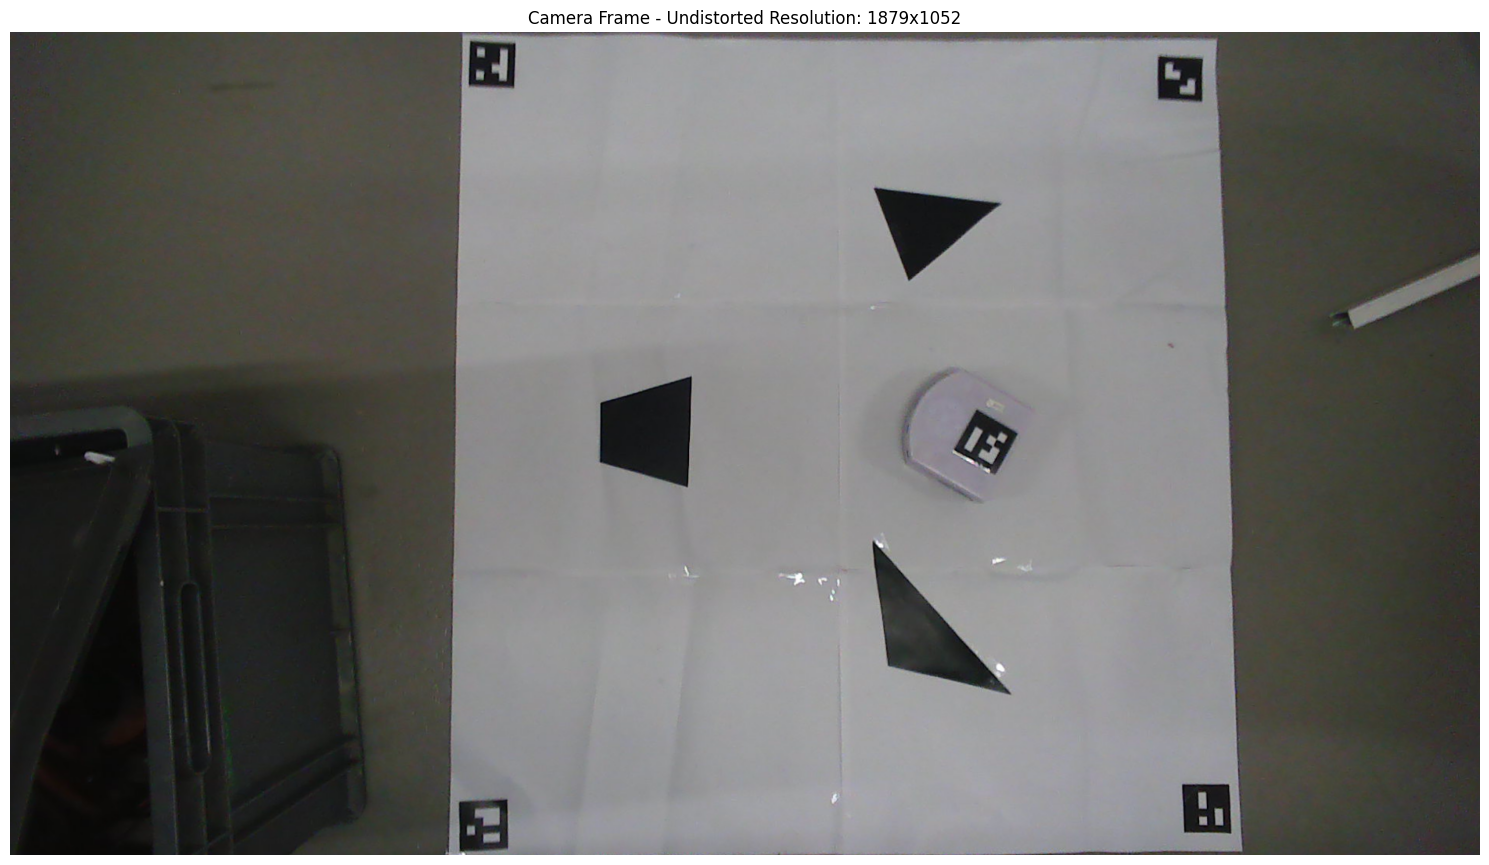

Frame shape (Height x Width x Channels): (1052, 1879, 3)
Frame captured successfully!


In [147]:
#RETESEER LES VALEURS DE LA CAMERA 

#=============================================
#Test of camera capture and undistortion
#=============================================

import matplotlib.pyplot as plt

# Capture frame from camera (undistorted frame)
frame = vision._get_frame()

if frame is not None:
    # Convert BGR (OpenCV) to RGB (matplotlib)
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    
    # Display the image
    plt.figure(figsize=(15, 10))
    plt.imshow(frame_rgb)
    plt.title(f"Camera Frame - Undistorted Resolution: {frame.shape[1]}x{frame.shape[0]}")
    plt.axis('off')
    plt.tight_layout()
    plt.show()
    
    print(f"Frame shape (Height x Width x Channels): {frame.shape}")
    print(f"Frame captured successfully!")
else:
    print("Failed to capture frame")

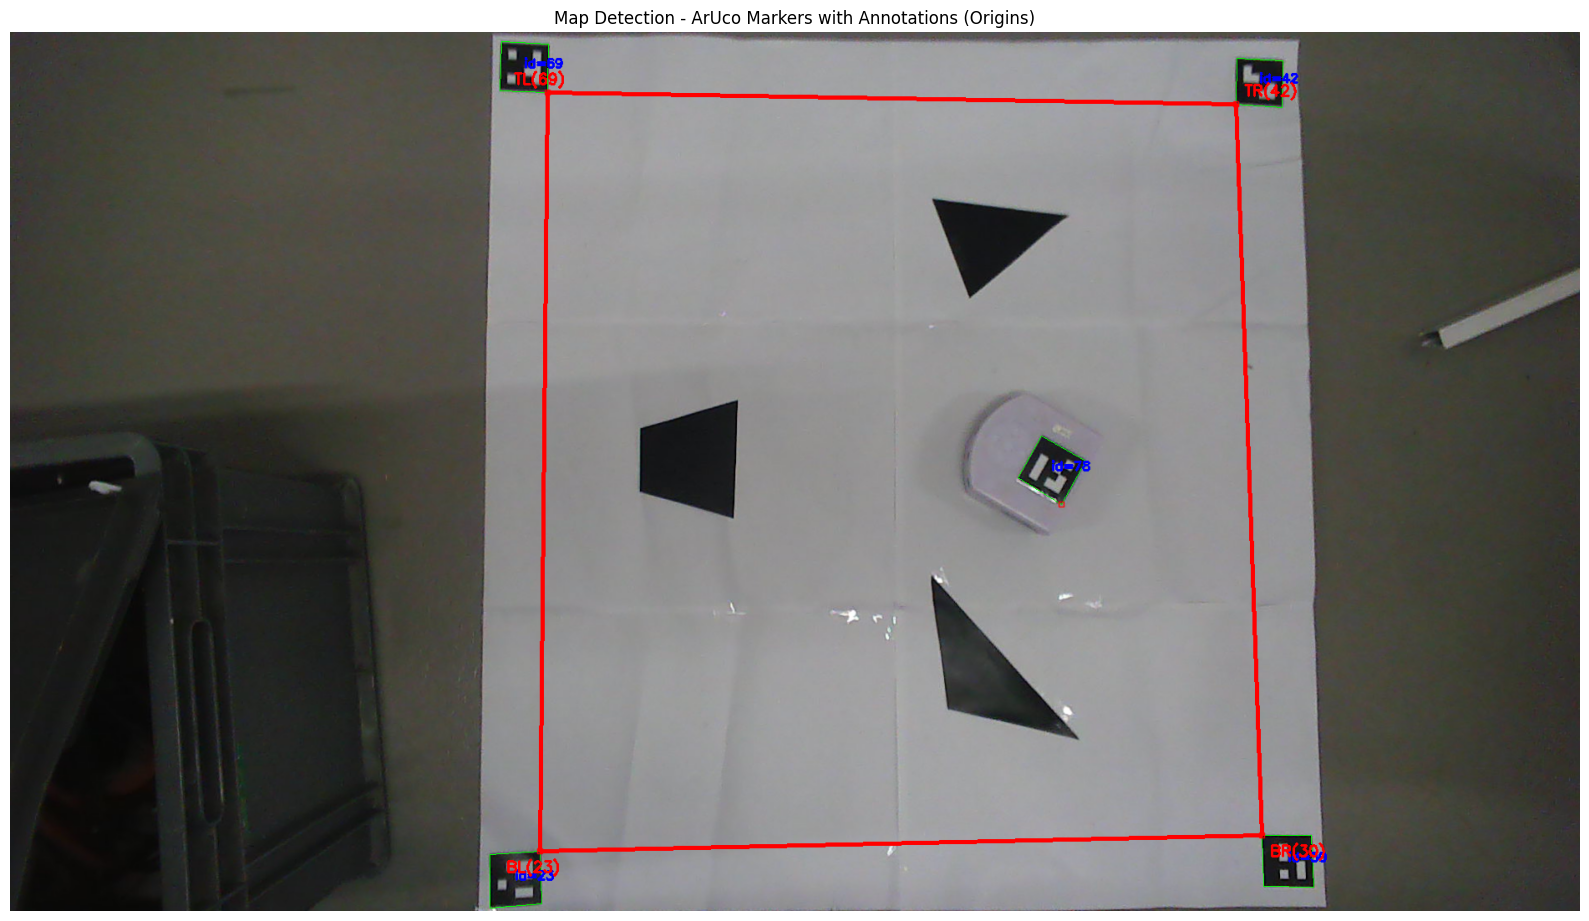

Detected ArUco marker origin positions (Top-Left corner):
  TL (69): (643.0, 72.0)
  TR (42): (1467.0, 86.0)
  BL (23): (634.0, 980.0)
  BR (30): (1498.0, 961.0)


In [149]:
#============================================
#Test of map detection with aruco markers
#============================================

import cv2
import matplotlib.pyplot as plt
import numpy as np
from src import utils

# Capture frame
before_map_crop = vision._get_frame()

if before_map_crop is not None:
    # Create a copy for drawing (before detection modifies the frame)
    frame_with_markers = before_map_crop.copy()
    
    # Detect ArUco markers (this will draw on the copy)
    img, corner_pos = vision._detect_map_markers(frame_with_markers)
    
    if corner_pos is not None:
        # Extract the 4 corner markers from dictionary in correct order [TL, TR, BL, BR]
        corners_array = np.array([
            corner_pos[69],  # TL
            corner_pos[42],  # TR
            corner_pos[23],  # BL
            corner_pos[30]   # BR
        ])
        
        # Draw red borders connecting the 4 corner markers using utils
        img = utils.draw_red_line_in_image(corners_array, img)
        
        # Convert BGR to RGB for matplotlib
        frame_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        # Display the result
        plt.figure(figsize=(16, 10))
        plt.imshow(frame_rgb)
        plt.title("Map Detection - ArUco Markers with Annotations (Origins)")
        plt.axis('off')
        plt.tight_layout()
        plt.show()
        
        # Print marker positions (origins = top-left corners)
        print("Detected ArUco marker origin positions (Top-Left corner):")
        for marker_id in [69, 42, 23, 30]:
            if marker_id in corner_pos:
                x, y = corner_pos[marker_id]
                marker_name = {69: "TL", 42: "TR", 23: "BL", 30: "BR"}[marker_id]
                print(f"  {marker_name} ({marker_id}): ({x:.1f}, {y:.1f})")
        
    else:
        print("Failed to detect all ArUco markers!")
        print("Make sure all 6 markers are visible: 69, 42, 23, 30 (corners), 78 (robot), 53 (goal)")
else:
    print("Failed to capture frame")

Capturing frame and computing bird's eye view...
Map dimension : None
Map dimension not provided!


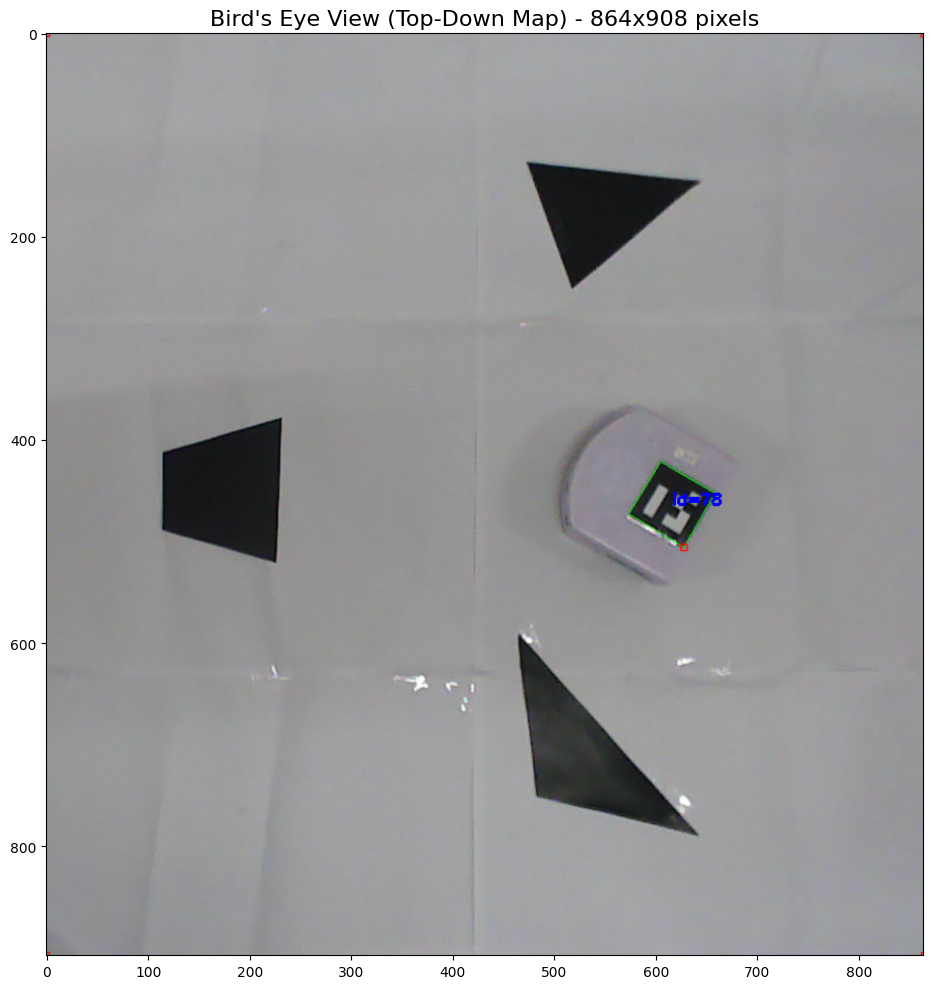


 Bird's eye view extracted successfully!
  Map dimensions: 864 x 908 pixels


In [150]:
#============================================
#Test: Bird's Eye View (Top-Down Map)
#============================================

import cv2
import matplotlib.pyplot as plt
import numpy as np

print("Capturing frame and computing bird's eye view...")

# Get bird's eye view directly (captures frame internally)
birds_eye_view = vision.get_birds_eye_view()

if birds_eye_view is not None:
    # Convert BGR to RGB for matplotlib display
    map_rgb = cv2.cvtColor(birds_eye_view, cv2.COLOR_BGR2RGB)
    
    # Get map dimensions
    height, width = birds_eye_view.shape[:2]
    
    # Display the bird's eye view map
    plt.figure(figsize=(14, 10))
    plt.imshow(map_rgb)
    plt.title(f"Bird's Eye View (Top-Down Map) - {width}x{height} pixels", fontsize=16)
    # plt.xlabel("X (pixels)", fontsize=12)
    # plt.ylabel("Y (pixels)", fontsize=12)
    # plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    print(f"\n Bird's eye view extracted successfully!")
    print(f"  Map dimensions: {width} x {height} pixels")  
else:
    print("✗ Failed to get bird's eye view.")
    print("  Make sure:")
    print("  - Camera is connected")
    print("  - All 4 corner markers are visible (IDs: 42, 30, 69, 23)")
    print("  - Markers are not obscured or too close to frame edges")


In [136]:
#============================================
# Test: Obstacle detection on bird's eye view
#============================================
import numpy as np
import cv2

MAP_SIZE_CM = (71.0, 71.0)  # Size of the map in centimeters (width, height)
print("="*50)
print("Obstacle Detection Test")
print("="*50)

# Step 1: Get bird's eye view and initialize pixels_per_cm
print("\n[1/4] Capturing bird's eye view...")
birds_eye_view = vision.get_birds_eye_view(map_dimension=MAP_SIZE_CM)

if birds_eye_view is None:
    print("✗ Failed to get bird's eye view. Exiting test.")
    exit(1)

print(f"✓ Bird's eye view captured: {birds_eye_view.shape}")
print(f"✓ Pixels per cm: {vision.pixels_per_cm:.2f} px/cm")

# Step 2: Detect obstacles and create binary occupancy grid
print("\n[2/4] Detecting obstacles and generating occupancy grid...")
occupancy_grid = vision.detect_obstacles(
    birds_eye_view, 
    robot_width_cm=11.0,
    return_colored=False  # Binary grid
)

if occupancy_grid is None:
    print("✗ Failed to generate occupancy grid. Exiting test.")
    exit(1)

# Step 3: Print statistics
print("\n[3/4] Occupancy grid statistics:")
total_cells = occupancy_grid.size
obstacle_cells = np.sum(occupancy_grid)
free_cells = total_cells - obstacle_cells
obstacle_percentage = (obstacle_cells / total_cells) * 100

print(f"  • Grid size: {occupancy_grid.shape[1]} x {occupancy_grid.shape[0]} pixels")
print(f"  • Total cells: {total_cells}")
print(f"  • Obstacle cells: {obstacle_cells} ({obstacle_percentage:.1f}%)")
print(f"  • Free cells: {free_cells} ({100-obstacle_percentage:.1f}%)")

# Step 4: Visualize results
print("\n[4/4] Visualizing results...")

# Option A: Visualize binary grid (black/white)
print("  → Displaying binary occupancy grid...")
vision.visualize_occupancy_grid(occupancy_grid, "Binary Occupancy Grid")

# Option B: Visualize colored grid (black/gray/white)
print("  → Generating colored visualization...")
colored_grid = vision.detect_obstacles(
    birds_eye_view,
    robot_width_cm=11.0,
    return_colored=True  # Colored visualization
)

if colored_grid is not None:
    print("  → Displaying colored grid (Black=Obstacle, Gray=Safety Margin, White=Free)")
    cv2.imshow("Colored Occupancy Grid", colored_grid)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

# Optional: Save results
print("\n[Optional] Saving results...")
cv2.imwrite("binary_occupancy_grid.png", (1 - occupancy_grid) * 255)
if colored_grid is not None:
    cv2.imwrite("colored_occupancy_grid.png", colored_grid)
print("✓ Results saved: binary_occupancy_grid.png, colored_occupancy_grid.png")

print("\n" + "="*50)
print("✓ Test completed successfully!")
print("="*50)

Obstacle Detection Test

[1/4] Capturing bird's eye view...
Failed to detect all required ArUco corner markers: [69, 42, 23, 30]
✗ Failed to get bird's eye view. Exiting test.


AttributeError: 'NoneType' object has no attribute 'shape'

In [ ]:
#============================================
#Test: Robot and Goal Detection 
#============================================
import numpy as np
import cv2

MAP_SIZE_CM = (71.0, 71.0)  # Size of the map in centimeters (width, height)
print("="*50)
print("Obstacle Detection Test")
print("="*50)

# Step 1: Get bird's eye view and initialize pixels_per_cm
print("\n[1/4] Capturing bird's eye view...")
birds_eye_view = vision.get_birds_eye_view(map_dimension=MAP_SIZE_CM)

if birds_eye_view is None:
    print("✗ Failed to get bird's eye view. Exiting test.")
    exit(1)



In [138]:
#Start of real code
MAP_SIZE_CM = (71.0, 71.0)

debug = False

#Important frame 
map_img = None 
occupancy_grid = None

#Important positions
robot_position = None  # numpy array [x, y, angle] 
goal_position = None

try: 
    #Camera connection
    print("Connexion to camera ...")
    if not vision.webcam_connextion():
        print("Failed to connect to camera")
        exit(1)

    # Get frame and detect markers
    input("Press Enter to capture frame and detect map markers...")

    # Call without arguments - it will capture frame internally
    map_img = vision.get_birds_eye_view() 
    
    if map_img is not None and debug: 
        cv2.imshow("Bird's Eye View Map", map_img)
        cv2.waitKey(0)
        cv2.destroyAllWindows()
    
    occupancy_grid = vision.detect_obstacles(map_img)
    
    if occupancy_grid is not None and debug:
        vision.visualize_occupancy_grid(occupancy_grid, "Occupancy Grid Visualization")

    input("Install Robot and Goal markers on the map and press Enter to continue... ")

    # Get robot position (returns image with drawn markers and position array)
    img_with_robot, robot_position = vision.get_robot_position(map_img)
    
    if robot_position is not None:
        print(f"Robot position: x={robot_position[0]:.1f}, y={robot_position[1]:.1f}, angle={robot_position[2]:.3f} rad")
        cv2.imshow("Bird's Eye View Map with Robot", img_with_robot)
        cv2.waitKey(0)
        cv2.destroyAllWindows()
    else:
        print("Robot marker not found!")

except KeyboardInterrupt:
    print("User interrupted the kernel. Closing the webcam...")

finally:
    # Release resources
    vision.disconnect_webcam() 


Connexion to camera ...
User interrupted the kernel. Closing the webcam...
User interrupted the kernel. Closing the webcam...
Webcam disconnected
Webcam disconnected


In [152]:
#============================================
#Test: Robot (Thymio) Position Detection
#============================================

import cv2
import matplotlib.pyplot as plt
import numpy as np

print("Testing robot (Thymio) marker detection...")

# Get bird's eye view
birds_eye_view = vision.get_birds_eye_view()

if birds_eye_view is not None:
    # Create a copy for visualization
    map_with_robot = birds_eye_view.copy()
    
    # Detect robot position
    robot_position = vision.get_robot_position(map_with_robot)
    
    if robot_position is not None:
        robot_x, robot_y = robot_position
        
        # Convert to scalar if needed
        robot_x = float(robot_x)
        robot_y = float(robot_y)
        
        # Draw robot position on map
        cv2.circle(map_with_robot, (int(robot_x), int(robot_y)), 10, (0, 255, 0), -1)  # Green circle
        cv2.circle(map_with_robot, (int(robot_x), int(robot_y)), 15, (0, 0, 255), 2)   # Red border
        
        # Add text label
        cv2.putText(map_with_robot, f"Robot (78)", (int(robot_x) + 20, int(robot_y) - 20),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)
        
        # Convert BGR to RGB for matplotlib
        map_rgb = cv2.cvtColor(map_with_robot, cv2.COLOR_BGR2RGB)
        
        # Display result
        plt.figure(figsize=(12, 10))
        plt.imshow(map_rgb)
        plt.title("Robot Detection - Thymio Position (Marker ID: 78)", fontsize=16)
        plt.axis('off')
        plt.tight_layout()
        plt.show()
        
        print(f"\n✓ Robot detected successfully!")
        print(f"  Position (pixels): ({robot_x:.1f}, {robot_y:.1f})")
        
        # Convert to cm if pixels_per_cm is available
        if vision.pixels_per_cm is not None:
            robot_x_cm = robot_x / vision.pixels_per_cm
            robot_y_cm = robot_y / vision.pixels_per_cm
            print(f"  Position (cm): ({robot_x_cm:.2f}, {robot_y_cm:.2f})")
    else:
        print("✗ Robot marker (ID: 78) not found!")
        print("  Make sure:")
        print("  - Robot marker is visible in the map area")
        print("  - Marker is not obscured or damaged")
        print("  - Marker ID is 78 (Thymio)")
else:
    print("✗ Failed to get bird's eye view.")


Testing robot (Thymio) marker detection...
Map dimension : None
Map dimension not provided!


TypeError: only length-1 arrays can be converted to Python scalars

In [111]:
import cv2
import numpy as np
import time

#Start of real code
MAP_SIZE_CM = (71.0, 71.0)

debug = False
REAL_TIME_TRACKING = True  # Flag to enable/disable real-time tracking
FPS_TARGET = 30  # Target frames per second for tracking

#Important frames 
map_img = None 
occupancy_grid = None

#Important positions
robot_position = None  # numpy array [x, y, angle] 
goal_position = None

# For FPS calculation
frame_count = 0
start_time = time.time()

try: 
    #Camera connection
    print("Connexion to camera ...")
    if not vision.webcam_connextion():
        print("Failed to connect to camera")
        exit(1)

    # Get frame and detect markers
    input("Press Enter to capture frame and detect map markers...")

    # Call without arguments - it will capture frame internally
    map_img = vision.get_birds_eye_view(map_dimension=MAP_SIZE_CM) 
    
    if map_img is not None and debug: 
        cv2.imshow("Bird's Eye View Map", map_img)
        cv2.waitKey(0)
        cv2.destroyAllWindows()
    
    occupancy_grid = vision.detect_obstacles(map_img)
    
    if occupancy_grid is not None and debug:
        vision.visualize_occupancy_grid(occupancy_grid, "Occupancy Grid Visualization")

    input("Install Robot and Goal markers on the map and press Enter to continue... ")

    if REAL_TIME_TRACKING:
        print("\n=== REAL-TIME TRACKING MODE ===")
        print("Press 'q' to quit tracking")
        print("Press 's' to save current frame")
        print("Press 'p' to pause/resume")
        print("================================\n")
        
        paused = False
        frame_delay = int(1000 / FPS_TARGET)  # Delay in ms for target FPS
        
        while True:
            if not paused:
                # Capture new frame and get bird's eye view
                current_map = vision.get_birds_eye_view(map_dimension=MAP_SIZE_CM)
                
                if current_map is not None:
                    # Get robot position on current frame
                    img_with_robot, robot_position = vision.get_robot_position(current_map)
                    
                    # Create display image with information overlay
                    display_img = img_with_robot.copy()
                    
                    if robot_position is not None:
                        # Add text overlay with robot information
                        x, y, angle = robot_position
                        angle_deg = np.degrees(angle)
                        
                        # Position info
                        cv2.putText(display_img, f"X: {x:.1f} px", (10, 30),
                                   cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
                        cv2.putText(display_img, f"Y: {y:.1f} px", (10, 60),
                                   cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
                        cv2.putText(display_img, f"Angle: {angle_deg:.1f} deg", (10, 90),
                                   cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
                        
                        # Convert to cm if pixels_per_cm is available
                        if vision.pixels_per_cm is not None:
                            x_cm = x / vision.pixels_per_cm
                            y_cm = y / vision.pixels_per_cm
                            cv2.putText(display_img, f"Pos: ({x_cm:.1f}, {y_cm:.1f}) cm", 
                                       (10, 120), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2)
                    else:
                        # Robot not detected
                        cv2.putText(display_img, "ROBOT NOT DETECTED", (10, 30),
                                   cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 0, 255), 2)
                    
                    # Calculate and display FPS
                    frame_count += 1
                    elapsed = time.time() - start_time
                    fps = frame_count / elapsed if elapsed > 0 else 0
                    cv2.putText(display_img, f"FPS: {fps:.1f}", (10, display_img.shape[0] - 10),
                               cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)
                    
                    # Show the frame
                    cv2.imshow("Real-Time Robot Tracking", display_img)
                else:
                    print("Warning: Could not capture frame")
            
            # Handle keyboard input
            key = cv2.waitKey(frame_delay) & 0xFF
            
            if key == ord('q'):
                print("\nQuitting real-time tracking...")
                break
            elif key == ord('s'):
                # Save current frame
                timestamp = time.strftime("%Y%m%d_%H%M%S")
                filename = f"robot_position_{timestamp}.png"
                cv2.imwrite(filename, display_img)
                print(f"Frame saved as {filename}")
            elif key == ord('p'):
                # Toggle pause
                paused = not paused
                status = "PAUSED" if paused else "RESUMED"
                print(f"Tracking {status}")
        
        cv2.destroyAllWindows()
        
        # Print final statistics
        print(f"\n=== TRACKING STATISTICS ===")
        print(f"Total frames processed: {frame_count}")
        print(f"Average FPS: {fps:.2f}")
        if robot_position is not None:
            print(f"Final robot position: x={robot_position[0]:.1f}, y={robot_position[1]:.1f}, angle={np.degrees(robot_position[2]):.1f}°")
        print("===========================\n")
    
    else:
        # Single shot mode (original behavior)
        # Get robot position (returns image with drawn markers and position array)
        img_with_robot, robot_position = vision.get_robot_position(map_img)
        
        if robot_position is not None:
            print(f"Robot position: x={robot_position[0]:.1f}, y={robot_position[1]:.1f}, angle={robot_position[2]:.3f} rad")
            print(f"Robot position: x={robot_position[0]:.1f}, y={robot_position[1]:.1f}, angle={np.degrees(robot_position[2]):.1f}°")
            
            cv2.imshow("Bird's Eye View Map with Robot", img_with_robot)
            cv2.waitKey(0)
            cv2.destroyAllWindows()
        else:
            print("Robot marker not found!")

except KeyboardInterrupt:
    print("\nUser interrupted the kernel. Closing the webcam...")
    cv2.destroyAllWindows()

except Exception as e:
    print(f"\nAn error occurred: {str(e)}")
    import traceback
    traceback.print_exc()
    cv2.destroyAllWindows()

finally:
    # Release resources
    vision.disconnect_webcam()
    print("Webcam disconnected successfully.")

Connexion to camera ...
Webcam connected successfully!
Webcam connected successfully!
Failed to detect all required ArUco corner markers: [69, 42, 23, 30]
Error: No bird's eye view image provided
Failed to detect all required ArUco corner markers: [69, 42, 23, 30]
Error: No bird's eye view image provided

=== REAL-TIME TRACKING MODE ===
Press 'q' to quit tracking
Press 's' to save current frame
Press 'p' to pause/resume

Failed to detect all required ArUco corner markers: [69, 42, 23, 30]
Failed to detect all required ArUco corner markers: [69, 42, 23, 30]

=== REAL-TIME TRACKING MODE ===
Press 'q' to quit tracking
Press 's' to save current frame
Press 'p' to pause/resume

Failed to detect all required ArUco corner markers: [69, 42, 23, 30]
Failed to detect all required ArUco corner markers: [69, 42, 23, 30]
Failed to detect all required ArUco corner markers: [69, 42, 23, 30]
Map dimension : (71.0, 71.0)
Failed to detect all required ArUco corner markers: [69, 42, 23, 30]
Map dimension

In [ ]:
#============================================
# Test: Obstacle detection on bird's eye view
#============================================
import numpy as np
import cv2

MAP_SIZE_CM = (71.0, 71.0)  # Size of the map in centimeters (width, height)
print("="*50)
print("Obstacle Detection Test")
print("="*50)

# Step 1: Get bird's eye view and initialize pixels_per_cm
print("\n[1/4] Capturing bird's eye view...")
birds_eye_view = vision.get_birds_eye_view(map_dimension=MAP_SIZE_CM)

if birds_eye_view is None:
    print("✗ Failed to get bird's eye view. Exiting test.")
    exit(1)

print(f"✓ Bird's eye view captured: {birds_eye_view.shape}")
print(f"✓ Pixels per cm: {vision.pixels_per_cm:.2f} px/cm")

# Step 2: Detect obstacles and create binary occupancy grid
print("\n[2/4] Detecting obstacles and generating occupancy grid...")
occupancy_grid = vision.detect_obstacles(
    birds_eye_view, 
    robot_width_cm=11.0  # Binary grid
)

if occupancy_grid is None:
    print("✗ Failed to generate occupancy grid. Exiting test.")
    exit(1)

# Step 3: Print statistics
print("\n[3/4] Occupancy grid statistics:")
total_cells = occupancy_grid.size
obstacle_cells = np.sum(occupancy_grid)
free_cells = total_cells - obstacle_cells
obstacle_percentage = (obstacle_cells / total_cells) * 100

print(f"  • Grid size: {occupancy_grid.shape[1]} x {occupancy_grid.shape[0]} pixels")
print(f"  • Total cells: {total_cells}")
print(f"  • Obstacle cells: {obstacle_cells} ({obstacle_percentage:.1f}%)")
print(f"  • Free cells: {free_cells} ({100-obstacle_percentage:.1f}%)")

# Step 4: Visualize results
print("\n[4/4] Visualizing results...")

# Option A: Visualize binary grid (black/white)
print("  → Displaying binary occupancy grid...")
vision.visualize_occupancy_grid(occupancy_grid, "Binary Occupancy Grid")

# Option B: Visualize colored grid (black/gray/white)
print("  → Generating colored visualization...")
colored_grid = vision.detect_obstacles(
    birds_eye_view,
    robot_width_cm=11.0,
    return_colored=True  # Colored visualization
)

if colored_grid is not None:
    print("  → Displaying colored grid (Black=Obstacle, Gray=Safety Margin, White=Free)")
    cv2.imshow("Colored Occupancy Grid", colored_grid)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

# Optional: Save results
print("\n[Optional] Saving results...")
cv2.imwrite("binary_occupancy_grid.png", (1 - occupancy_grid) * 255)
if colored_grid is not None:
    cv2.imwrite("colored_occupancy_grid.png", colored_grid)
print("✓ Results saved: binary_occupancy_grid.png, colored_occupancy_grid.png")

print("\n" + "="*50)
print("✓ Test completed successfully!")
print("="*50)

Obstacle Detection Test

[1/4] Capturing bird's eye view...
Map dimension : (71.0, 71.0)
✓ Bird's eye view captured: (908, 864, 3)
✓ Pixels per cm: 12.48 px/cm

[2/4] Detecting obstacles and generating occupancy grid...


TypeError: Vision.detect_obstacles() got an unexpected keyword argument 'return_colored'